# Exploratory Data Analysis — Power System Load Type

## Objective
Understand the historical power-system dataset and identify reliable features for classifying `Load_Type` as `Light_Load`, `Medium_Load`, or `Maximum_Load`.

The assignment specifies using the last month as the final test set. This notebook performs EDA and documents the data-quality decisions used in the modeling notebook. Raw plots are exploratory and may be distorted by corrupted readings identified below.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
candidates = [Path("../data/load_data.csv"), Path("data/load_data.csv"),
              Path("load_data.csv"), Path("/mnt/data/load_data.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find load_data.csv. Put it in data/ or ../data/.")
print("Using:", DATA_PATH.resolve())

raw = pd.read_csv(DATA_PATH)
raw["Date_Time"] = pd.to_datetime(raw["Date_Time"], dayfirst=True, errors="coerce")
raw = raw.dropna(subset=["Date_Time"]).sort_values("Date_Time")
print("Raw shape:", raw.shape)
display(raw.head())

Using: /home/sahil/assignment-2 1/data/load_data.csv
Raw shape: (35041, 9)


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
95,2018-01-01 00:00:00,3.420000,3.46,0.0,0.0,70.30,291.49819,0.000000,Light_Load
0,2018-01-01 00:15:00,8.753692,2.95,0.0,0.0,73.21,100.00000,900.000000,Light_Load
1,2018-01-01 00:30:00,4.000000,4.46,0.0,0.0,66.77,100.00000,1800.000000,Light_Load
2,2018-01-01 00:45:00,3.240000,3.28,0.0,0.0,70.28,100.00000,8070.880991,Light_Load
3,2018-01-01 01:00:00,3.310000,3.56,0.0,0.0,68.09,100.00000,3600.000000,Light_Load


## 1. Dataset structure and data quality

The data is recorded every 15 minutes across 2018. We check the target distribution, missing values, repeated timestamps, and continuity before drawing conclusions.

In [2]:
print("Rows, columns:", raw.shape)
print("Date range:", raw["Date_Time"].min(), "to", raw["Date_Time"].max())
print("Missing values:")
display(raw.isna().sum().rename("missing_count").to_frame())
print("Target distribution:")
display(raw["Load_Type"].value_counts(dropna=False).rename("count").to_frame())
print("Duplicate timestamps:", raw["Date_Time"].duplicated().sum())

Rows, columns: (35041, 9)
Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00
Missing values:


,missing_count
Date_Time,0
Usage_kWh,1559
Lagging_Current_Reactive.Power_kVarh,876
Leading_Current_Reactive_Power_kVarh,1156
CO2(tCO2),455
Lagging_Current_Power_Factor,350
Leading_Current_Power_Factor,1471
NSM,455
Load_Type,0


Target distribution:


,count
Load_Type,
Light_Load,18073
Medium_Load,9696
Maximum_Load,7272


Duplicate timestamps: 1


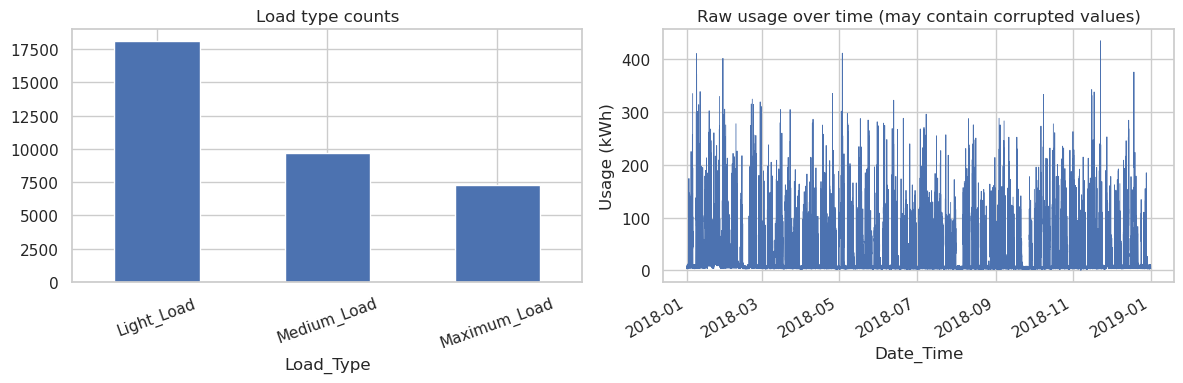

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
raw["Load_Type"].value_counts().reindex(["Light_Load", "Medium_Load", "Maximum_Load"]).plot(kind="bar", ax=axes[0])
axes[0].set_title("Load type counts")
axes[0].tick_params(axis="x", rotation=20)
raw.set_index("Date_Time")["Usage_kWh"].plot(ax=axes[1], linewidth=0.6)
axes[1].set_title("Raw usage over time (may contain corrupted values)")
axes[1].set_ylabel("Usage (kWh)")
plt.tight_layout()
plt.show()

## 2. Resolve duplicate timestamps

The file has one repeated timestamp. To retain the most complete observation, we sort rows by their count of missing fields and keep the row with fewer missing values. After deduplication, the expected number of 15-minute records is 35,040.

In [4]:
n_missing = raw.drop(columns="Date_Time").isna().sum(axis=1)
df = (raw.assign(_n=n_missing).sort_values(["Date_Time", "_n"])
        .drop_duplicates("Date_Time", keep="first")
        .drop(columns="_n").set_index("Date_Time").sort_index())
assert df.index.is_unique
assert len(df) == 35040, f"Expected 35,040 rows; found {len(df)}"
assert (df.index.to_series().diff().dropna() == pd.Timedelta("15min")).all()
print("Rows after deduplication:", len(df))
print("All timestamps unique and spaced 15 minutes apart.")

Rows after deduplication: 35040
All timestamps unique and spaced 15 minutes apart.


## 3. Corrupted readings and physical consistency

`NSM` should equal seconds since midnight. Power factors must lie between 0 and 100. Some readings have more than two decimal places even though the meter-like values are expected to be reported to two decimals; this is used as a corruption flag, not proof that every such value is wrong. `CO2` is approximately proportional to usage, so it is largely redundant.

In [5]:
VALUE_RENAME = {
    "Lagging_Current_Reactive.Power_kVarh": "Lag_kVarh",
    "Leading_Current_Reactive_Power_kVarh": "Lead_kVarh",
    "CO2(tCO2)": "CO2",
    "Lagging_Current_Power_Factor": "Lag_PF",
    "Leading_Current_Power_Factor": "Lead_PF",
}
df = df.rename(columns=VALUE_RENAME)
value_cols = ["Usage_kWh", "Lag_kVarh", "Lead_kVarh", "CO2", "Lag_PF", "Lead_PF"]

def spurious(s, decimals=2):
    x = s * (10 ** decimals)
    return ((x - np.round(x)).abs() > 1e-5) & s.notna()

flag = pd.DataFrame({c: spurious(df[c]) for c in value_cols})
display(flag.mean().rename("fraction_flagged").to_frame().round(3))
print("NSM > 86,400:", (df["NSM"] > 86400).sum())
print("Lagging PF > 100:", (df["Lag_PF"] > 100).sum())
print("Leading PF > 100:", (df["Lead_PF"] > 100).sum())

,fraction_flagged
Usage_kWh,0.096
Lag_kVarh,0.077
Lead_kVarh,0.032
CO2,0.039
Lag_PF,0.099
Lead_PF,0.095


NSM > 86,400: 1773
Lagging PF > 100: 3225
Leading PF > 100: 2685


In [6]:
df["NSM_rebuilt"] = df.index.hour * 3600 + df.index.minute * 60
ok = df["NSM"].notna() & df["NSM"].between(0, 86400)
print("NSM matches timestamp among in-range nonmissing values:",
      (df.loc[ok, "NSM"] == df.loc[ok, "NSM_rebuilt"]).mean().round(4))

u = df["Usage_kWh"]
lag_q = df["Lag_kVarh"]
lead_q = df["Lead_kVarh"]
def pf_from(u, q):
    den = np.sqrt(u**2 + q**2)
    return (100*u/den).mask(den == 0, 0.0)

for name, qcol, pfcol in [("lagging", "Lag_kVarh", "Lag_PF"),
                           ("leading", "Lead_kVarh", "Lead_PF")]:
    calculated = pf_from(df["Usage_kWh"], df[qcol])
    gap = (calculated - df[pfcol]).abs()
    valid = calculated.notna() & df[pfcol].notna()
    print(f"{name} PF median absolute formula difference:",
          gap[valid].median().round(3))
print("Correlation Usage vs CO2:", df[["Usage_kWh", "CO2"]].corr().iloc[0,1].round(4))

NSM matches timestamp among in-range nonmissing values: 0.95
lagging PF median absolute formula difference: 0.003
leading PF median absolute formula difference: 0.0
Correlation Usage vs CO2: 0.8288


## 4. Load type and time patterns

The target varies strongly by time of day and month. We inspect hourly averages and the distribution of labels by hour, weekday/weekend, and month. These patterns motivate timestamp-derived features.

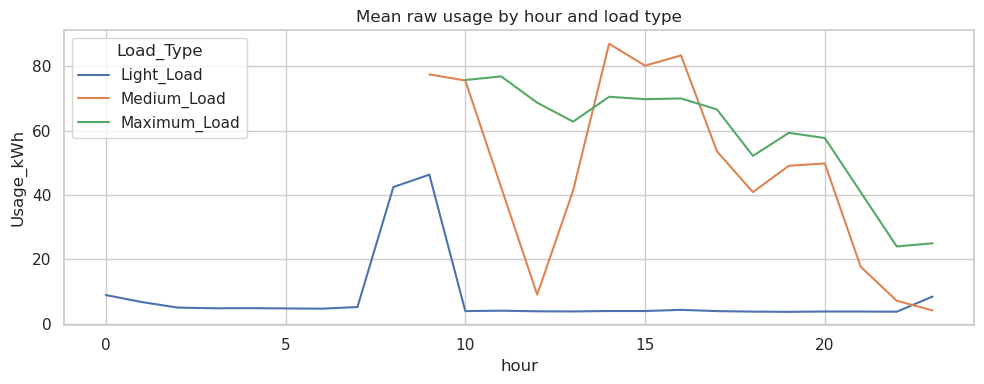

Load_Type,Light_Load,Maximum_Load,Medium_Load
month,,,
1,0.492,0.218,0.290
2,0.604,0.170,0.226
3,0.473,0.226,0.301
4,0.475,0.225,0.300
5,0.511,0.210,0.280
6,0.514,0.208,0.278
7,0.454,0.234,0.312
8,0.567,0.185,0.247
9,0.553,0.192,0.256


Load_Type,Light_Load,Maximum_Load,Medium_Load
weekday,,,
0,0.450,0.236,0.314
1,0.450,0.236,0.314
2,0.450,0.236,0.314
3,0.439,0.240,0.321
4,0.439,0.240,0.321
5,0.574,0.183,0.244
6,0.809,0.082,0.109


In [7]:
plot_df = df.copy()
plot_df["hour"] = plot_df.index.hour
plot_df["weekday"] = plot_df.index.dayofweek
plot_df["month"] = plot_df.index.month
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=plot_df, x="hour", y="Usage_kWh", hue="Load_Type",
             estimator="mean", errorbar=None, ax=ax)
ax.set_title("Mean raw usage by hour and load type")
plt.tight_layout()
plt.show()

display(pd.crosstab(plot_df["month"], plot_df["Load_Type"], normalize="index").round(3))
display(pd.crosstab(plot_df["weekday"], plot_df["Load_Type"], normalize="index").round(3))

## 5. Electrical feature relationships

Usage, reactive power and CO₂ tend to be related to load intensity, but the classes overlap and some readings are missing or corrupted. Leading/lagging power factor and reactive power are therefore useful candidates to compare, rather than assuming any single electrical feature perfectly identifies the class.

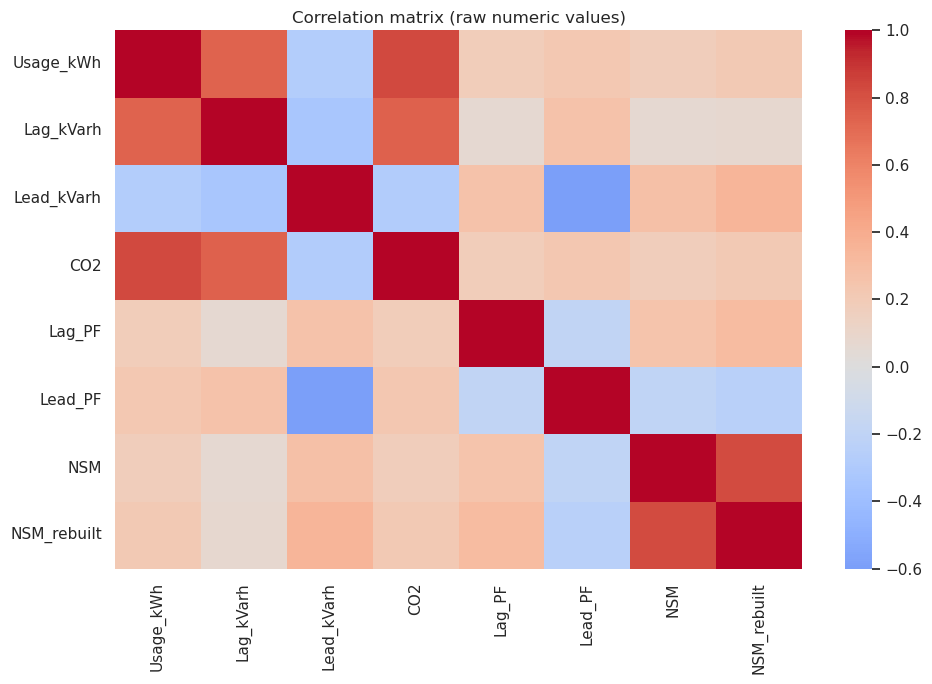

,Usage_kWh,Lag_kVarh,Lead_kVarh,CO2,Lag_PF,Lead_PF
Load_Type,,,,,,
Light_Load,3.42,4.57,0.00,0.00,69.87,100.0
Maximum_Load,58.90,27.40,0.00,0.03,92.50,100.0
Medium_Load,35.93,6.16,0.29,0.02,98.58,100.0


In [8]:
numeric = df.select_dtypes(include="number").columns
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric].corr(), cmap="coolwarm", center=0)
plt.title("Correlation matrix (raw numeric values)")
plt.tight_layout()
plt.show()

display(df.groupby("Load_Type")[value_cols].median().round(3))

## 6. Seasonal schedule and off-day exploration

A useful pattern in the earlier analysis was a different daily schedule for March–October versus November–February. Some days have `Light_Load` for every timestamp. This is a descriptive EDA label pattern; do **not** use a flag constructed from the target as a model feature.

In [9]:
df["month"] = df.index.month
df["hour"] = df.index.hour
df["weekday"] = df.index.dayofweek
df["season"] = np.where(df["month"].between(3, 10), "summer", "winter")
df["date"] = df.index.normalize()

per_day = df.groupby("date")["Load_Type"].agg(
    all_light=lambda s: (s == "Light_Load").all(),
    weekday=lambda s: s.index[0].dayofweek,
    month=lambda s: s.index[0].month,
)
print("All-Light days:", int(per_day["all_light"].sum()), "of", len(per_day))
print("All-Light days by weekday (0=Mon, 6=Sun):")
display(per_day[per_day["all_light"]].groupby("weekday").size().rename("all_light_days").to_frame())
print("All-Light dates:")
print([d.strftime("%Y-%m-%d") for d in per_day.index[per_day["all_light"]]])

All-Light days: 62 of 365
All-Light days by weekday (0=Mon, 6=Sun):


,all_light_days
weekday,
0,3
1,3
2,3
3,2
4,2
5,14
6,35


All-Light dates:
['2018-01-01', '2018-01-06', '2018-01-07', '2018-01-21', '2018-02-04', '2018-02-10', '2018-02-11', '2018-02-14', '2018-02-15', '2018-02-16', '2018-02-17', '2018-02-18', '2018-02-25', '2018-03-04', '2018-03-18', '2018-03-31', '2018-04-01', '2018-04-15', '2018-04-29', '2018-05-01', '2018-05-05', '2018-05-06', '2018-05-13', '2018-05-27', '2018-06-02', '2018-06-03', '2018-06-09', '2018-06-10', '2018-06-17', '2018-07-01', '2018-07-22', '2018-08-01', '2018-08-02', '2018-08-03', '2018-08-04', '2018-08-05', '2018-08-12', '2018-08-19', '2018-08-25', '2018-09-16', '2018-09-22', '2018-09-23', '2018-09-24', '2018-09-25', '2018-09-26', '2018-09-30', '2018-10-07', '2018-10-14', '2018-10-21', '2018-10-28', '2018-11-11', '2018-11-24', '2018-11-25', '2018-12-02', '2018-12-09', '2018-12-15', '2018-12-22', '2018-12-23', '2018-12-25', '2018-12-29', '2018-12-30', '2018-12-31']


In [10]:
# Schedule purity is computed descriptively on non-all-Light days.
day_light = df.groupby("date")["Load_Type"].transform(lambda s: (s == "Light_Load").all())
working = df.loc[~day_light].copy()
working["tod"] = working.index.strftime("%H:%M")
working["season"] = np.where(working.index.month >= 3, "summer", "winter")
working.loc[working.index.month >= 11, "season"] = "winter"
counts = working.groupby(["season", "tod"])["Load_Type"].nunique()
print("Fraction of season/time slots with a single observed class:",
      (counts == 1).mean().round(4))
schedule = working.groupby(["season", "tod"])["Load_Type"].agg(lambda s: s.mode().iloc[0])
display(schedule.rename("most_common_label").reset_index().head(20))

Fraction of season/time slots with a single observed class: 1.0


,season,tod,most_common_label
0,summer,00:00,Light_Load
1,summer,00:15,Light_Load
2,summer,00:30,Light_Load
3,summer,00:45,Light_Load
4,summer,01:00,Light_Load
5,summer,01:15,Light_Load
6,summer,01:30,Light_Load
7,summer,01:45,Light_Load
8,summer,02:00,Light_Load
9,summer,02:15,Light_Load


## 7. Day-level activity features

Earlier exploration found that median daytime usage and its 90th percentile can distinguish many all-Light days from working days. These are potentially useful **retrospective** features because they summarize later measurements in the same day. For real-time prediction, prefer rolling features based only on readings available up to the prediction timestamp.

day_med                                                  day_p90  \
            count   mean    std   min    25%    50%    75%     max   count   
all_light                                                                    
False       303.0  49.90  24.26  3.64  41.35  51.62  61.16  114.66   303.0   
True         62.0   3.38   0.54  2.68   3.02   3.18   3.70    5.08    62.0   

                                                             
            mean    std   min    25%    50%     75%     max  
all_light                                                    
False      91.21  31.43  7.69  67.80  93.70  113.00  214.35  
True        5.25   1.65  3.42   3.81   4.85    6.53   10.47

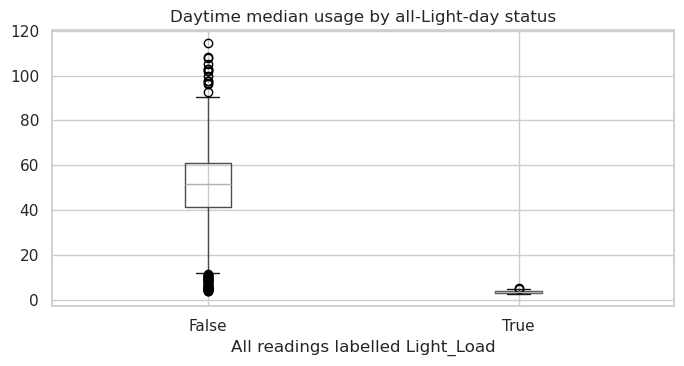

In [11]:
daytime = df["Usage_kWh"].where(((df.index.hour >= 10) & (df.index.hour <= 22)))
day_features = pd.DataFrame({
    "day_med": daytime.groupby(df.index.normalize()).median(),
    "day_p90": daytime.groupby(df.index.normalize()).quantile(0.9),
}).join(per_day["all_light"])
display(day_features.groupby("all_light")[["day_med", "day_p90"]].describe().round(2))
ax = day_features.boxplot(column="day_med", by="all_light", figsize=(7, 4))
ax.set_title("Daytime median usage by all-Light-day status")
ax.set_xlabel("All readings labelled Light_Load")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 8. EDA conclusions and modeling plan

1. The dataset contains 35,040 quarter-hour records after resolving one duplicate timestamp.
2. Several numeric fields contain missing or suspect values. Rebuild `NSM` from the timestamp, flag excess-precision values, and set impossible power factors to missing before imputation.
3. `CO2` is strongly related to `Usage_kWh` and may add little independent information.
4. `Load_Type` is structured by time of day and season. Weekday/weekend and day-level activity may improve classification.
5. Compare time-only, electrical-only, combined retrospective features, and causal trailing-usage features.
6. Use January–November for training/model selection and December as the final test month. Report accuracy, precision, recall and F1-score, including class-level metrics.
7. A feature built from the target (such as an `all_light` flag) must never be used as a predictor. Full-day activity features must be clearly described as retrospective rather than real-time.